# Mon Pokédex Pokémon : notebook 2, images (niveau 2)

**Module :** Apprentissage automatique

**Objectif :** à partir d'une **image** de Pokémon de 1ʳᵉ génération, prédire son ou ses **types**. Le modèle sera intégré à l'application, qui garde aussi toutes les fonctionnalités du niveau 1.

**Exigence centrale du sujet : la couverture.** Le modèle ne doit pas seulement bien marcher sur quelques Pokémon faciles. Il doit produire des prédictions fiables sur **le plus grand nombre possible de Pokémon**. On mesurera donc les performances **Pokémon par Pokémon**, et pas seulement globalement.

**Plan du notebook**

| Partie | Contenu |
|---|---|
| 0 | Données : téléchargement, association aux lignes du CSV, nettoyage, exploration |
| 1 | Formulation (multi-label ou espèce) et découpage train/validation/test |
| 2 | Référence classique : histogrammes de couleurs + HOG, puis SVM, Random Forest, logistique |
| 3 | CNN entraîné de zéro |
| 4 | Transfer learning (MobileNetV3, EfficientNet) |
| 5 | Évaluation, couverture et Grad-CAM |
| 6 | Choix final et sauvegarde |

**Matériel.** Tout tourne sur **CPU** : 4 cœurs, sans GPU. Les mesures préalables donnent, en 224×224, environ 6 ms par image en inférence pour MobileNetV3-Large et environ 33 ms par image pour un pas de fine-tuning complet. Une époque sur environ 10 000 images prend donc à peu près 6 minutes, ce qui est raisonnable. Le code tourne à l'identique sur Google Colab si l'on veut aller plus vite.

**Reproductibilité :** `random_state = 42` partout (découpage, augmentation, initialisation des réseaux).

In [1]:
import sys, warnings, os
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from src.config import RANDOM_STATE, TYPE_FR
from src.preprocessing import load_clean
from src.image_utils import (IMAGES_RAW, IMAGES_INDEX, ROOT_DIR, match_folders, normalize_name,
                             load_rgb, to_square, min_hamming_to_others, prepare_dataset,
                             SEUIL_MEME_ESPECE, SEUIL_AUTRE_ESPECE)
from src.viz import set_style, save_fig, SERIES, INK_2, MUTED, COLOR_NON_LEG, COLOR_LEG

set_style()
pd.set_option("display.max_colwidth", 80)
np.random.seed(RANDOM_STATE)
pokemon = load_clean()

## 0. Données images

### 0.1 Téléchargement

Le dataset Kaggle « Pokemon Images First Generation (17000 files) » est une archive d'environ **3 Go**. Elle contient un dossier par Pokémon, rempli d'images de sources variées : artworks officiels, sprites de jeux, cartes, fan-arts, captures d'animé.

- **Il n'est pas versionné dans git**, à cause de sa taille. La fonction `prepare_dataset()` de `src/image_utils.py` le télécharge, le nettoie et l'exporte. On peut aussi la lancer en ligne de commande : `python -m src.image_utils`.
- **Seul l'inventaire `data/images_index.csv` est versionné.** Il donne, pour chaque fichier, la décision prise (gardé ou retiré) et son motif.

In [2]:
REBUILD = not IMAGES_INDEX.exists()       # mettre True pour tout refaire (≈ 2 min)
if REBUILD:
    index = prepare_dataset()
else:
    index = pd.read_csv(IMAGES_INDEX, keep_default_na=False, na_values=[""])
print(f"{len(index)} fichiers dans l'archive, répartis dans {index['folder'].nunique()} dossiers")

17263 fichiers dans l'archive, répartis dans 143 dossiers


### 0.2 Associer chaque dossier à sa ligne de `pokemon.csv`

Les noms de dossiers ne s'écrivent pas toujours comme dans le CSV : « Mr. Mime » ou « MrMime » contre « Mr. Mime », « Farfetchd » contre « Farfetch'd », « Nidoran♀ »… On compare donc des **noms normalisés** : minuscules, sans accents ni ponctuation, avec ♀ remplacé par « f » et ♂ par « m ».

In [3]:
assoc, non_apparies, manquants = match_folders(IMAGES_RAW, pokemon)
diff = assoc[assoc["folder"] != assoc["name"]]
print("Dossiers dont le nom diffère du CSV (appariés grâce à la normalisation) :")
display(diff[["folder", "name", "pokedex_number"]].assign(
    clé=[normalize_name(f) for f in diff["folder"]]).set_index("folder"))
print(f"Dossiers non appariés : {non_apparies if non_apparies else 'aucun'}")
plusieurs = assoc.groupby("pokedex_number")["folder"].apply(list).loc[lambda s: s.str.len() > 1]
print("Pokémon répartis sur plusieurs dossiers (fusionnés) :", plusieurs.to_dict())
print(f"\nPokémon de 1re génération sans AUCUN dossier ({len(manquants)}) :")
manquants.assign(types=manquants["type1"].map(TYPE_FR) + np.where(manquants["type2"] != "aucun",
                 " / " + manquants["type2"].map(TYPE_FR), "")).drop(columns=["type1", "type2"]).set_index("pokedex_number")

Dossiers dont le nom diffère du CSV (appariés grâce à la normalisation) :


,name,pokedex_number,clé
folder,,,
Farfetchd,Farfetch'd,83,farfetchd
MrMime,Mr. Mime,122,mrmime


Dossiers non appariés : aucun
Pokémon répartis sur plusieurs dossiers (fusionnés) : {122: ['Mr. Mime', 'MrMime']}

Pokémon de 1re génération sans AUCUN dossier (9) :


,name,types
pokedex_number,,
29,Nidoran♀,Poison
32,Nidoran♂,Poison
46,Paras,Insecte / Plante
53,Persian,Normal
76,Golem,Roche / Sol
89,Muk,Poison
95,Onix,Roche / Sol
98,Krabby,Eau
140,Kabuto,Roche / Eau


**Lecture**

- **Tous les dossiers sont appariés** grâce à la normalisation des noms. Mr. Mime est réparti sur **deux dossiers** (« Mr. Mime » et « MrMime ») : ses images sont fusionnées.
- **Neuf Pokémon de la 1ʳᵉ génération n'ont aucune image** dans l'archive : Nidoran♀, Nidoran♂, Paras, Persian, Grolem, Grotadmorv, Onix, Krabby et Kabuto. Le dataset contient donc **142 espèces**, et non 151.
- **Conséquences :**
  - un modèle qui identifie l'**espèce** (approche B, partie 1) ne pourra **jamais** reconnaître ces 9 Pokémon ;
  - un modèle qui prédit directement les **types** (approche A) le pourra peut-être : Onix ressemble à d'autres types Roche/Sol, Persian à d'autres Normal. C'est un premier argument pour l'approche A, à reprendre en partie 1.

**Correction des étiquettes de type.** Pour 14 Pokémon de 1ʳᵉ génération, le CSV donne en `type2` un type de leur **forme d'Alola**. Par exemple, Rattata est noté Normal / Ténèbres et Osselait Sol / Feu. Parfois, `type2` répète simplement `type1` (Raichu Électrik / Électrik). Or les images montrent les formes **classiques**. Sans correction, on apprendrait au modèle de **faux types**. La correction est faite une fois pour toutes dans `clean()` (`src/preprocessing.py`), qui rétablit les types officiels.

In [4]:
from src.preprocessing import KANTO_SINGLE_TYPE, load_raw
brut = load_raw().set_index("name")
corr = pokemon[pokemon["name"].isin(KANTO_SINGLE_TYPE)].set_index("name")
pd.DataFrame({"type1": corr["type1"].map(TYPE_FR), "type2 dans le CSV": brut.loc[corr.index, "type2"].map(TYPE_FR),
              "type2 corrigé": corr["type2"].map(TYPE_FR)}).T

name,Rattata,Raticate,Raichu,Sandshrew,Sandslash,Vulpix,Ninetales,Diglett,Dugtrio,Meowth,Persian,Grimer,Muk,Marowak
type1,Normal,Normal,Électrik,Sol,Sol,Feu,Feu,Sol,Sol,Normal,Normal,Poison,Poison,Sol
type2 dans le CSV,Ténèbres,Ténèbres,Électrik,Glace,Glace,Glace,Glace,Sol,Sol,Ténèbres,Ténèbres,Poison,Poison,Feu
type2 corrigé,(aucun),(aucun),(aucun),(aucun),(aucun),(aucun),(aucun),(aucun),(aucun),(aucun),(aucun),(aucun),(aucun),(aucun)


### 0.3 Inventaire : formats, tailles, fichiers corrompus

Chaque fichier est **entièrement décodé** : `verify()` contrôle l'intégrité, puis le décodage complet détecte les fichiers tronqués. On relève son format réel, son mode de couleur et sa taille.

In [5]:
lisibles = index[~index["motif"].fillna("").str.startswith("illisible")]
print("Fichiers illisibles ou non images :")
display(index[index["motif"].fillna("").str.startswith("illisible")][["path", "motif"]])
fmt = lisibles.groupby(["format", "mode"]).size().rename("fichiers").sort_values(ascending=False).to_frame()
ext_reelle = lisibles["path"].str.extract(r"\.(\w+)$")[0].str.lower().replace({"jpg": "jpeg"})
print(f"Extension différente du format réel : {(ext_reelle != lisibles['format'].str.lower()).sum()} fichiers"
      " (ex. un .png qui est en réalité un JPEG)")
print(f"Images avec transparence : {lisibles['transparency'].sum()} | GIF animés : {(lisibles['n_frames'] > 1).sum()}")
display(fmt.T)
lisibles[["width", "height"]].describe(percentiles=[0.05, 0.5, 0.95]).round(0).T

Fichiers illisibles ou non images :


,path,motif
58,pokemon/Abra/desktop.ini,illisible : format non image
6597,pokemon/Ivysaur/00000212.png,illisible : SyntaxError: not a TIFF file (header b'\x00\x08\x00\x07\x01\x12\...
15126,pokemon/Tentacruel/d6fb0a3046364ea2b49525c6f6b966e5.svg,illisible : format non image


Extension différente du format réel : 303 fichiers (ex. un .png qui est en réalité un JPEG)
Images avec transparence : 4645 | GIF animés : 302


format     JPEG   PNG        GIF  PNG BMP JPEG PNG   
mode        RGB  RGBA   RGB    P    P RGB    L  LA  L
fichiers  11047  3929  1240  771  249  11    7   5  1

,count,mean,std,min,5%,50%,95%,max
width,17260.0,686.0,492.0,43.0,162.0,601.0,1480.0,10000.0
height,17260.0,633.0,421.0,42.0,158.0,600.0,1220.0,7419.0


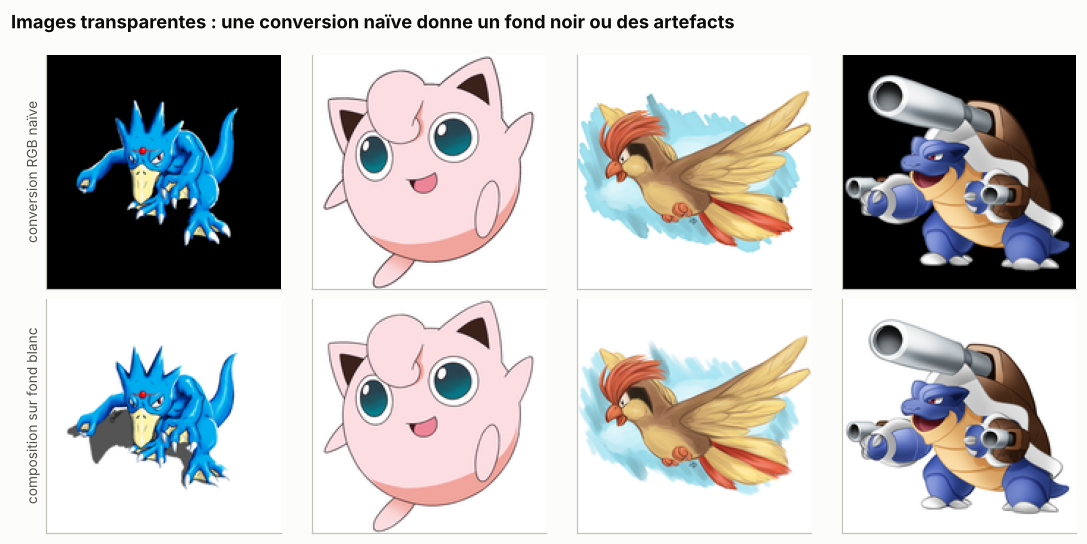

In [6]:
# Pourquoi composer la transparence sur un fond blanc ?
ex = lisibles[lisibles["transparency"]].sample(4, random_state=RANDOM_STATE)
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for k, p in enumerate(ex["path"]):
    im = Image.open(ROOT_DIR / "data" / "images" / p)
    if getattr(im, "n_frames", 1) > 1:
        im.seek(0)
    axes[0, k].imshow(to_square(im.convert("RGB"), 160))          # conversion naïve
    axes[1, k].imshow(to_square(load_rgb(ROOT_DIR / "data" / "images" / p), 160))
    for a in axes[:, k]:
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
axes[0, 0].set_ylabel("conversion RGB naïve", fontsize=9)
axes[1, 0].set_ylabel("composition sur fond blanc", fontsize=9)
fig.suptitle("Images transparentes : une conversion naïve donne un fond noir ou des artefacts",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "n2_01_transparence")
plt.show()

**Lecture**

- **3 fichiers sont inutilisables** : un `desktop.ini` (fichier système Windows), un dessin vectoriel `.svg` et un PNG corrompu, dont l'en-tête est invalide.
- **Les formats sont très variés.** On trouve du JPEG, du PNG (RGB, RGBA ou à palette), des GIF dont certains animés, quelques BMP et images en niveaux de gris. Environ **300 fichiers ont une extension trompeuse**, par exemple un `.png` qui est en fait un JPEG. On se fie donc au **format réel** lu par Pillow, jamais à l'extension.
- **Les tailles vont de 42 à 10 000 pixels de côté.** On ramène toutes les images à **224 × 224**, la taille d'entrée des réseaux pré-entraînés sur ImageNet. Pour cela, on **complète** l'image en carré avec du blanc **sans la déformer**, puis on la redimensionne. On évite le recadrage, qui pourrait couper le Pokémon.
- **Environ 4 600 images sont transparentes.** Une conversion RGB naïve rend le fond **noir** ou fait apparaître des artefacts de couleur, et le modèle risquerait d'apprendre que « fond noir = image PNG ». On compose donc sur **fond blanc**, ce qui correspond au fond le plus fréquent des artworks.
- **GIF animés** : on garde la première image.
- **Tout le prétraitement est fait par une seule fonction** (`load_rgb` puis `to_square`), réutilisée telle quelle par l'appli. C'est la même logique que le `Pipeline` du niveau 1 : on évite tout écart entre l'entraînement et l'utilisation réelle.

### 0.4 Doublons et quasi-doublons

**Pourquoi c'est crucial.** Si une même image, ou une version à peine recadrée, se retrouve à la fois dans le train et dans le test, le modèle sera évalué sur des images **déjà vues**. Le score sera trop optimiste : c'est une **fuite de données**.

**Deux empreintes**

- **MD5 du fichier** : deux fichiers identiques octet par octet sont des **doublons exacts**.
- **Hash perceptuel (pHash)** : l'image est réduite et passée en niveaux de gris. On calcule une **transformée en cosinus discrète** (DCT, la même que pour la compression JPEG), et on garde les basses fréquences, c'est-à-dire la structure globale de l'image. Chaque coefficient est comparé à la médiane pour former 64 bits. Deux images **visuellement proches** ont des hash proches, même si l'une est redimensionnée, recompressée ou légèrement retouchée. La proximité se mesure par la **distance de Hamming**, le nombre de bits différents sur 64.

**Choix des seuils.** Pour chaque image, on calcule sa distance minimale à une image **de la même espèce** et à une image **d'une autre espèce**. Des distances très faibles entre espèces différentes signalent soit une **erreur d'étiquette**, soit une image peu informative.

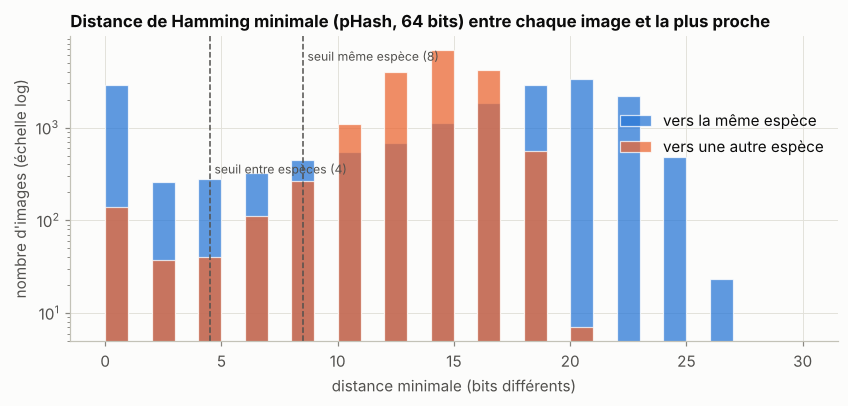

Doublons exacts (même espèce, d = 0) : 2886 images | même image dans 2 espèces (d = 0) : 140


In [7]:
cand = index[~index["motif"].fillna("").str.startswith(("illisible", "image vide", "dossier"))].reset_index(drop=True)
meme, autre = min_hamming_to_others(cand["phash"].tolist(), cand["pokedex_number"].to_numpy())
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(0, 31)
ax.hist(np.clip(meme, 0, 30), bins=bins, color=SERIES[0], alpha=0.75, label="vers la même espèce",
        edgecolor="white", linewidth=0.8)
ax.hist(np.clip(autre, 0, 30), bins=bins, color=SERIES[1], alpha=0.75, label="vers une autre espèce",
        edgecolor="white", linewidth=0.8)
for s, lab, y in [(SEUIL_AUTRE_ESPECE, "seuil entre espèces", 0.55), (SEUIL_MEME_ESPECE, "seuil même espèce", 0.92)]:
    ax.axvline(s + 0.5, color=INK_2, ls="--", lw=1)
    ax.text(s + 0.7, y, f"{lab} ({s})", fontsize=8, color=INK_2, transform=ax.get_xaxis_transform())
ax.set_yscale("log")
ax.set(title="Distance de Hamming minimale (pHash, 64 bits) entre chaque image et la plus proche",
       xlabel="distance minimale (bits différents)", ylabel="nombre d'images (échelle log)")
ax.legend(loc="upper right", bbox_to_anchor=(1, 0.8))
save_fig(fig, "n2_02_distances_phash")
plt.show()
print(f"Doublons exacts (même espèce, d = 0) : {(meme == 0).sum()} images "
      f"| même image dans 2 espèces (d = 0) : {(autre == 0).sum()}")

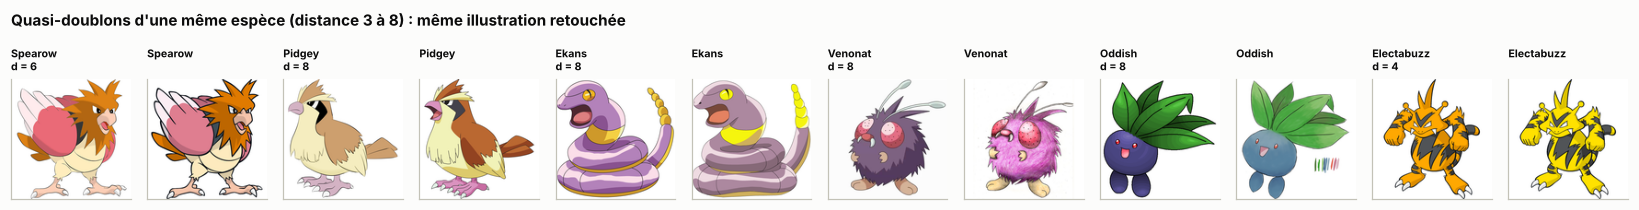

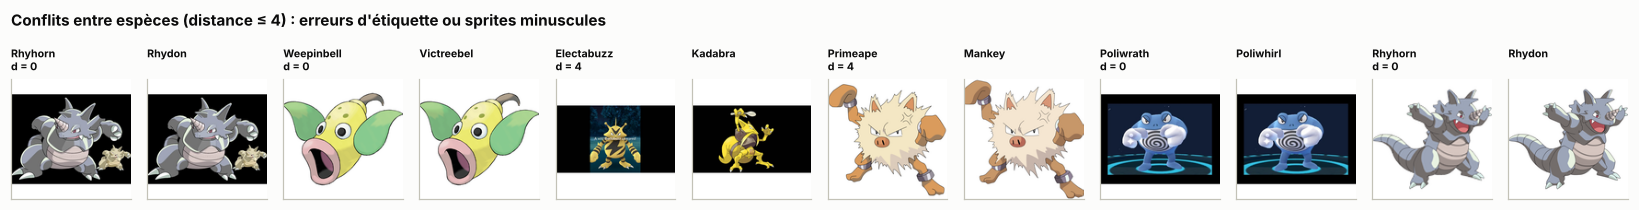

In [8]:
def planche(paires, titre, nom, n=6, S=130):
    fig, axes = plt.subplots(1, 2 * n, figsize=(2 * n * 1.25, 2.1))
    for k, (a, b, d) in enumerate(paires[:n]):
        for j, idx in enumerate((a, b)):
            ax = axes[2 * k + j]
            ax.imshow(to_square(load_rgb(ROOT_DIR / "data" / "images" / cand.loc[idx, "path"]), S))
            ax.set_title(f"{cand.loc[idx, 'folder'][:10]}" + (f"\nd = {d}" if j == 0 else "\n"), fontsize=7)
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    fig.suptitle(titre, x=0.01, ha="left", fontweight="bold", fontsize=10)
    fig.tight_layout()
    save_fig(fig, nom)
    plt.show()

h = np.array([int(x, 16) for x in cand["phash"]], dtype=np.uint64)
sp = cand["pokedex_number"].to_numpy()
rng = np.random.default_rng(RANDOM_STATE)

def exemples(meme_espece, lo, hi, n=6):
    out = []
    for i in rng.permutation(len(h)):
        d = np.bitwise_count(h ^ h[i]).astype(int); d[i] = 99
        m = (d >= lo) & (d <= hi) & ((sp == sp[i]) if meme_espece else (sp != sp[i]))
        if m.any():
            out.append((i, int(np.nonzero(m)[0][0]), int(d[np.nonzero(m)[0][0]])))
        if len(out) >= n:
            break
    return out

planche(exemples(True, 3, 8), f"Quasi-doublons d'une même espèce (distance 3 à {SEUIL_MEME_ESPECE}) : même illustration retouchée",
        "n2_03_quasi_doublons")
planche(exemples(False, 0, SEUIL_AUTRE_ESPECE), f"Conflits entre espèces (distance ≤ {SEUIL_AUTRE_ESPECE}) : erreurs d'étiquette ou sprites minuscules",
        "n2_04_conflits_especes")

**Lecture et règles retenues**

- **Entre images de la même espèce**, les distances faibles (≤ 8) correspondent presque toujours à la **même illustration** recadrée, recompressée, recolorée ou légèrement retouchée (voir la première planche).
  - **Règle :** on regroupe ces quasi-doublons (seuil de 8 bits, groupes = composantes connexes par union-find) et on **ne garde que la plus grande image de chaque groupe**.
  - Ainsi, chaque illustration n'apparaît **qu'une fois** dans tout le dataset, et ne peut pas se retrouver à la fois dans le train et dans le test.
- **Entre espèces différentes**, une distance très faible (≤ 4) révèle deux situations (voir la seconde planche) :
  - de **vraies erreurs d'étiquette** : la même image de Roucool rangée dans Roucoups, la même image de Férosinge rangée dans Colossinge, des images de **lignées d'évolution** entières ;
  - de **fausses alertes** : des sprites minuscules sur un grand fond blanc, ou des cartes Pokémon à la mise en page identique, dont les pHash se ressemblent.

  **Règle prudente :** on retire **toutes** les images concernées. On ne peut pas savoir laquelle des deux étiquettes est juste, et une image minuscule apporte de toute façon peu d'information.
- **Au-delà de 9 ou 10 bits**, les distances entre espèces différentes deviennent fréquentes et relèvent du hasard. Le hash ne permet plus de conclure, et on s'arrête donc à ces seuils prudents.

### 0.5 Bilan du nettoyage

In [9]:
index["décision"] = index["motif"].fillna("").replace("", "gardée")
index.loc[index["décision"].str.startswith("illisible"), "décision"] = "illisible / non image"
bilan = index["décision"].value_counts().rename("fichiers").to_frame()
bilan["%"] = (bilan["fichiers"] / len(index) * 100).round(1)
display(bilan)

garde = index[index["garde"]].copy()
print(f"Dataset final : {len(garde)} images, {garde['pokedex_number'].nunique()} espèces "
      f"({len(garde) / len(index):.0%} des fichiers d'origine)")

,fichiers,%
décision,,
gardée,14715,85.2
doublon exact,1174,6.8
quasi-doublon,1153,6.7
conflit entre espèces,217,1.3
illisible / non image,3,0.0
image vide,1,0.0


Dataset final : 14715 images, 142 espèces (85% des fichiers d'origine)


### 0.6 Exploration du dataset nettoyé

Images par Pokémon : min 56, médiane 103, max 165 (rapport max/min = 2.9)


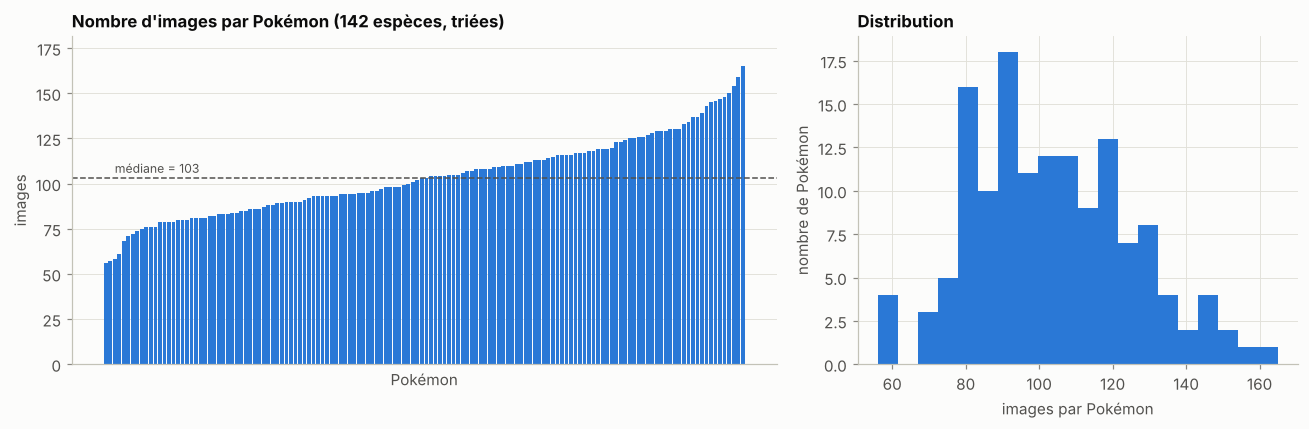

Les moins représentés : Seel (56), Abra (57), Electrode (58), Seaking (61), Gloom (68), Slowbro (71)
Les plus représentés  : Psyduck (165), Pikachu (159), Jigglypuff (154), Scyther (150), Vaporeon (148), Snorlax (147)


In [10]:
par_poke = garde.groupby(["pokedex_number", "name"]).size().rename("images").reset_index()
print(f"Images par Pokémon : min {par_poke['images'].min()}, médiane {par_poke['images'].median():.0f}, "
      f"max {par_poke['images'].max()} (rapport max/min = {par_poke['images'].max() / par_poke['images'].min():.1f})")
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax = axes[0]
p = par_poke.sort_values("images")
ax.bar(range(len(p)), p["images"], color=SERIES[0], width=0.85)
ax.axhline(p["images"].median(), color=INK_2, ls="--", lw=1)
ax.text(2, p["images"].median() + 3, f"médiane = {p['images'].median():.0f}", fontsize=8, color=INK_2)
ax.set(title="Nombre d'images par Pokémon (142 espèces, triées)", xlabel="Pokémon", ylabel="images",
       ylim=(0, p["images"].max() * 1.1))
ax.set_xticks([])
ax.grid(axis="x", visible=False)

ax = axes[1]
ax.hist(p["images"], bins=20, color=SERIES[0], edgecolor="white")
ax.set(title="Distribution", xlabel="images par Pokémon", ylabel="nombre de Pokémon")
fig.tight_layout()
save_fig(fig, "n2_05_images_par_pokemon")
plt.show()
print("Les moins représentés :", ", ".join(f"{n} ({k})" for n, k in p.head(6)[["name", "images"]].values))
print("Les plus représentés  :", ", ".join(f"{n} ({k})" for n, k in p.tail(6)[::-1][["name", "images"]].values))

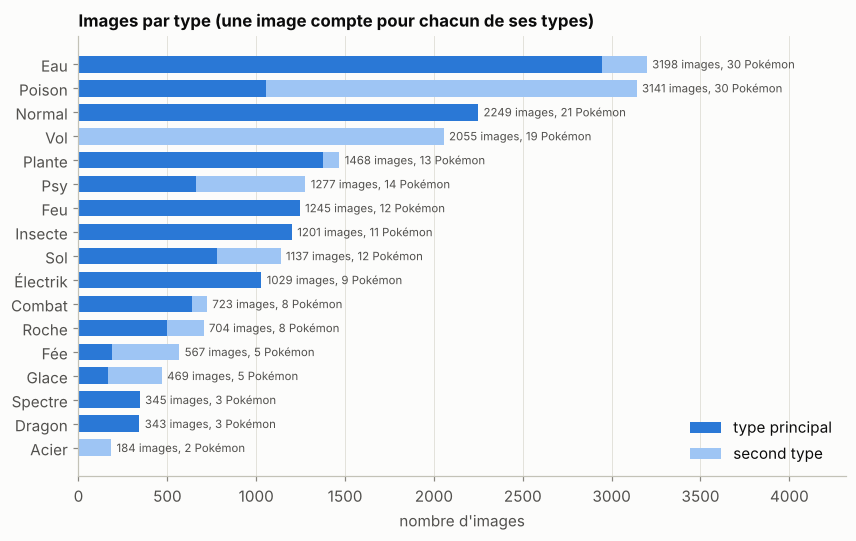

Pokémon à deux types : 63 sur 142 (44%) | images de Pokémon à deux types : 45%
Types absents en type principal mais présents en second type : ['Vol', 'Acier']


In [11]:
# Par type : une image compte pour chacun de ses types (problème multi-label)
lignes = []
for t in sorted(set(garde["type1"]) | set(garde["type2"]) - {"aucun"}):
    m1, m2 = garde["type1"] == t, garde["type2"] == t
    pokes = garde.loc[m1 | m2, "pokedex_number"].nunique()
    lignes.append({"type": TYPE_FR[t], "images (type 1)": int(m1.sum()), "images (type 2)": int(m2.sum()),
                   "images au total": int((m1 | m2).sum()), "Pokémon": pokes})
par_type = pd.DataFrame(lignes).set_index("type").sort_values("images au total")

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(par_type.index, par_type["images (type 1)"], color=SERIES[0], height=0.7, label="type principal")
ax.barh(par_type.index, par_type["images (type 2)"], left=par_type["images (type 1)"], color="#9ec5f4",
        height=0.7, label="second type")
for i, (tot, n) in enumerate(zip(par_type["images au total"], par_type["Pokémon"])):
    ax.text(tot + 30, i, f"{tot} images, {n} Pokémon", va="center", fontsize=7.5, color=INK_2)
ax.set(title="Images par type (une image compte pour chacun de ses types)", xlabel="nombre d'images",
       xlim=(0, par_type["images au total"].max() * 1.35))
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save_fig(fig, "n2_06_images_par_type")
plt.show()

n_types = (garde.drop_duplicates("pokedex_number")["type2"] != "aucun")
print(f"Pokémon à deux types : {n_types.sum()} sur {len(n_types)} ({n_types.mean():.0%}) "
      f"| images de Pokémon à deux types : {(garde['type2'] != 'aucun').mean():.0%}")
print("Types absents en type principal mais présents en second type :",
      [TYPE_FR[t] for t in set(garde["type2"]) - set(garde["type1"]) - {"aucun"}])

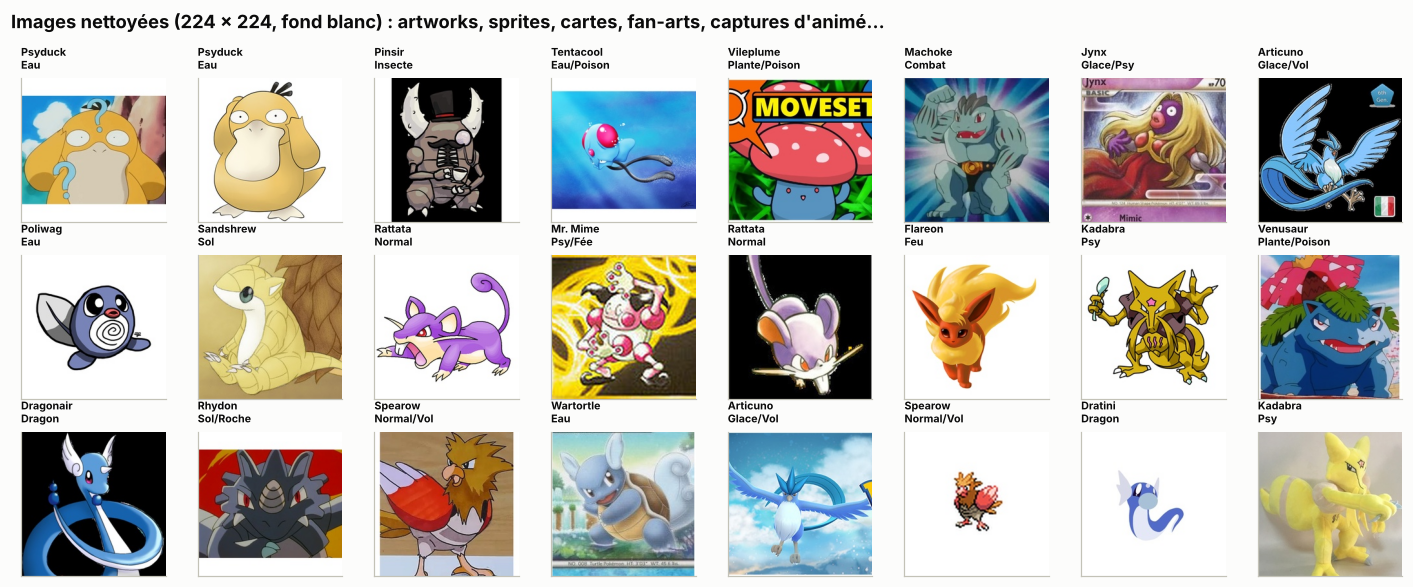

In [12]:
# Exemples d'images nettoyées (ce que verra le modèle)
ex = garde.sample(24, random_state=RANDOM_STATE)
fig, axes = plt.subplots(3, 8, figsize=(13, 5.4))
for ax, (_, r) in zip(axes.flat, ex.iterrows()):
    ax.imshow(Image.open(ROOT_DIR / r["clean_path"]))
    t = TYPE_FR[r["type1"]] + ("/" + TYPE_FR[r["type2"]] if r["type2"] != "aucun" else "")
    ax.set_title(f"{r['name']}\n{t}", fontsize=7)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Images nettoyées (224 × 224, fond blanc) : artworks, sprites, cartes, fan-arts, captures d'animé…",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "n2_07_exemples")
plt.show()

**Lecture**

- **Images par Pokémon :** le déséquilibre est **modéré**, avec un rapport d'environ 3 entre le Pokémon le moins représenté (environ 55 images) et le plus représenté (environ 165). Les Pokémon populaires (Pikachu, starters, Mewtwo…) ont plus d'images. Les moins représentés seront probablement plus difficiles à reconnaître, ce que la couverture devra vérifier.
- **Images par type :** le déséquilibre est **fort**. Eau, Poison, Normal et Vol dépassent 2 000 images, tandis qu'Acier, Dragon, Spectre, Glace et Fée en ont moins de 600.
  - En 1ʳᵉ génération, certains types n'existent **qu'en second type** : Vol (Roucool, Nosferapti…) et Acier (Magnéti et Magnéton, Électrik/Acier).
  - Les types rares reposent sur **très peu de Pokémon différents** : 2 pour Acier (Magnéti, Magnéton), 3 pour Dragon et Spectre, 5 pour Fée et Glace. Apprendre le type « Dragon » revient à apprendre Minidraco, Draco et Dracolosse. C'est un défi pour l'approche A sur des Pokémon jamais vus (partie 1).
- **Près de la moitié des Pokémon (44 %) ont deux types**, ce qui confirme la formulation **multi-label**.
- **Les images sont très hétérogènes** : artworks officiels, sprites pixelisés, cartes à jouer, fan-arts, captures d'animé, peluches… C'est **réaliste** pour la caméra du niveau 3, mais difficile. Le fond, le style et le cadrage varient beaucoup.

### 0.7 Synthèse des données

| Étape | Résultat |
|---|---|
| Archive | 17 263 fichiers, 143 dossiers, environ 3 Go |
| Association avec le CSV | 143 dossiers → **142 espèces** (Mr. Mime réparti sur 2 dossiers). **9 Pokémon sans aucune image** |
| Fichiers inutilisables | 3 (desktop.ini, svg, PNG corrompu) + 1 image vide |
| Doublons exacts / quasi-doublons d'une même espèce | retirés, on garde une image par groupe (pHash, seuil de 8 bits) |
| Conflits entre espèces | retirés (pHash, seuil de 4 bits) : erreurs d'étiquette ou sprites minuscules |
| **Dataset final** | **environ 14 700 images**, de 224 × 224, sur fond blanc |
| Étiquettes de type | 14 Pokémon corrigés (types de forme d'Alola dans le CSV) |
| Déséquilibre | modéré par Pokémon (de 56 à 165 images, rapport ≈ 3), **fort par type** |